# Cat Bond – ILS Structuring & Quantitative Pricing

## How would an investment bank structure and price a catastrophe bond on Atlantic hurricane risk?

The insurance industry faces a fundamental asymmetry: it receives regular premiums, but it is exposed to huge financial shocks when a major natural catastrophe happens (hurricanes, earthquakes). To avoid ruin, insurers transfer part of this tail risk to financial markets through securitisation: these are Insurance-Linked Securities (ILS).

The flagship product of this asset class is the Catastrophe Bond (Cat Bond). Its main appeal for institutional investors (hedge funds, pension funds) is that it is almost uncorrelated with traditional financial markets: a stock market crash does not trigger a hurricane.

In this project, I tried to put myself in the shoes of an arranger in an investment bank and to cover the whole pipeline:

1. Loss model: calibrate the frequency and the severity of major hurricanes on NOAA data, and simulate 10,000 years of losses.
2. Structuring: split the risk into three tranches inside a Special Purpose Vehicle (SPV).
3. Collateral: protect the capital of the SPV against interest rate risk with a Total Return Swap (TRS).
4. Pricing: compute the yield paid to investors on each tranche.

### 1. The data: NOAA HURDAT2

We use the HURDAT2 database of the NOAA (National Oceanic and Atmospheric Administration), which records every Atlantic storm every 6 hours since 1851. We only keep data from 1980 onwards, to rely on satellite-era observations, and we only keep the records where the storm has the hurricane status (`HU`).

The raw file is downloaded and parsed once, then saved as a CSV.

In [1]:
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CSV_FILE = "hurdat2_1980_2025.csv"
HURDAT2_URL = "https://www.nhc.noaa.gov/data/hurdat/hurdat2-1851-2025-02272026.txt"

def fetch_parse_and_save_hurdat2(url, start_year=1980, output_filename=CSV_FILE):
    """Download the raw HURDAT2 text file, parse it and keep hurricane records since start_year."""
    response = urllib.request.urlopen(url)
    lines = [line.decode("utf-8").strip() for line in response.readlines()]

    data = []
    current_storm_id = current_storm_name = current_storm_year = None
    for line in lines:
        if not line:
            continue
        parts = [p.strip() for p in line.split(",")]

        # header line of a new storm, e.g. "AL041980, ALLEN, 70,"
        if len(parts) >= 3 and parts[0].startswith("AL") and len(parts[0]) == 8:
            current_storm_id = parts[0]
            current_storm_name = parts[1]
            current_storm_year = int(parts[0][4:8])
        elif current_storm_year is not None and current_storm_year >= start_year:
            try:
                data.append({
                    "Storm_ID": current_storm_id,
                    "Name": current_storm_name,
                    "Year": current_storm_year,
                    "Date": parts[0],
                    "Status": parts[3],
                    "Max_Wind_knots": int(parts[6]) if parts[6] != "-999" else np.nan,
                    "Min_Pressure_mb": int(parts[7]) if parts[7] != "-999" else np.nan,
                })
            except (IndexError, ValueError):
                continue

    df = pd.DataFrame(data)
    df["Date"] = pd.to_datetime(df["Date"], format="%Y%m%d")
    df = df[df["Status"] == "HU"]
    df.to_csv(output_filename, index=False)
    return df

if os.path.exists(CSV_FILE):
    hurdat = pd.read_csv(CSV_FILE)
else:
    hurdat = fetch_parse_and_save_hurdat2(HURDAT2_URL)

print(f"{len(hurdat):,} hurricane records, {hurdat['Storm_ID'].nunique()} hurricanes, "
      f"from {hurdat['Year'].min()} to {hurdat['Year'].max()}")

4,912 hurricane records, 315 hurricanes, from 1980 to 2025


### 2. Calibration of the loss model

The aggregate loss $S$ of the portfolio over one year is a compound process:

$$S = \sum_{i=1}^{N} L_i$$

where $N$ is the number of events in the year and $L_i$ the financial loss caused by the $i$-th event. We model an insured portfolio with a Total Insured Value (TIV) of **5 billion dollars**, exposed to major hurricanes (Category 3 and above, i.e. winds ≥ 96 knots).

#### 2.1. Severity: Pareto distribution and Hill estimator

For each hurricane, we keep the maximum wind speed it reached. The wind speed of major hurricanes is modelled with a Pareto Type I distribution, which is well suited to fat tails:

$$f(x) = \frac{\alpha \, x_m^{\alpha}}{x^{\alpha+1}} \quad \text{for } x \ge x_m$$

with $x_m = 96$ knots. To find $\alpha$, we use the maximum likelihood (Hill) estimator:

$$\hat{\alpha} = \frac{n}{\sum_{i=1}^{n} \ln(x_i / x_m)}$$

#### 2.2. Frequency: Poisson distribution

The number of major hurricanes per year follows a Poisson distribution, and the natural estimator of $\lambda$ is the average number of major hurricanes per year. The frequency must be computed on the **same events** as the severity: only hurricanes reaching 96 knots.

In [2]:
XM = 96          # threshold of a major hurricane (knots)

max_wind_per_storm = hurdat.groupby("Storm_ID")["Max_Wind_knots"].max()
storm_year = hurdat.groupby("Storm_ID")["Year"].first()
n_years = hurdat["Year"].max() - hurdat["Year"].min() + 1

major = max_wind_per_storm[max_wind_per_storm >= XM]
n_major = len(major)

lambda_major = n_major / n_years                       # Poisson frequency
alpha = n_major / np.sum(np.log(major / XM))           # Hill / MLE estimator

print(f"Period: {n_years} years | all hurricanes: {len(max_wind_per_storm)} | major hurricanes: {n_major}")
print(f"Frequency  λ = {lambda_major:.3f} major hurricanes per year (Atlantic basin)")
print(f"Severity   α = {alpha:.4f} (Pareto tail index, xm = {XM} knots)")

Period: 46 years | all hurricanes: 315 | major hurricanes: 134
Frequency  λ = 2.913 major hurricanes per year (Atlantic basin)
Severity   α = 4.3816 (Pareto tail index, xm = 96 knots)


We find $\hat{\alpha} \approx 4.38$. This value above 4 is reassuring: the extreme risk exists, but the tail of the distribution is not infinite.

#### 2.3. Probability that a hurricane hits the portfolio

Not every major hurricane in the Atlantic basin hits our portfolio: most of them stay at sea or make landfall elsewhere. If we assume that every hurricane hits it, the expected annual loss becomes larger than the value of the portfolio itself.

We assume that the portfolio is exposed to the US Atlantic and Gulf coast, and that it is hit by every major hurricane making landfall in the US. According to NOAA, a major hurricane makes landfall in the US **about once every three years**. The hit probability is therefore:

$$p = \frac{1/3}{\hat{\lambda}}$$

and the number of events hitting the portfolio each year follows a Poisson distribution of parameter $\lambda \times p$. This is a conservative assumption, as a single landfall would never destroy a whole portfolio spread along the coast.

In [3]:
US_MAJOR_LANDFALLS_PER_YEAR = 1 / 3            # NOAA: about one major US landfall every three years
hit_prob = US_MAJOR_LANDFALLS_PER_YEAR / lambda_major
lambda_hit = lambda_major * hit_prob

print(f"Hit probability p = {hit_prob:.1%}")
print(f"Events hitting the portfolio: λ × p = {lambda_hit:.3f} per year")

Hit probability p = 11.4%
Events hitting the portfolio: λ × p = 0.333 per year


#### 2.4. The damage function (vulnerability curve)

Once the wind speed is simulated, we need to turn it into financial damage. A linear relation would be a mistake: the pressure of the wind grows in a non-linear way. We use a cubic vulnerability curve, which gives a Damage Ratio (DR) between 0% and 100%:

$$DR(v) = \min\left(\frac{\max(v - x_m, 0)}{v_{max} - x_m}, 1\right)^3$$

where $v_{max} = 165$ knots is the threshold of total destruction. The loss of one event is $L_i = DR(v_i) \times TIV$.

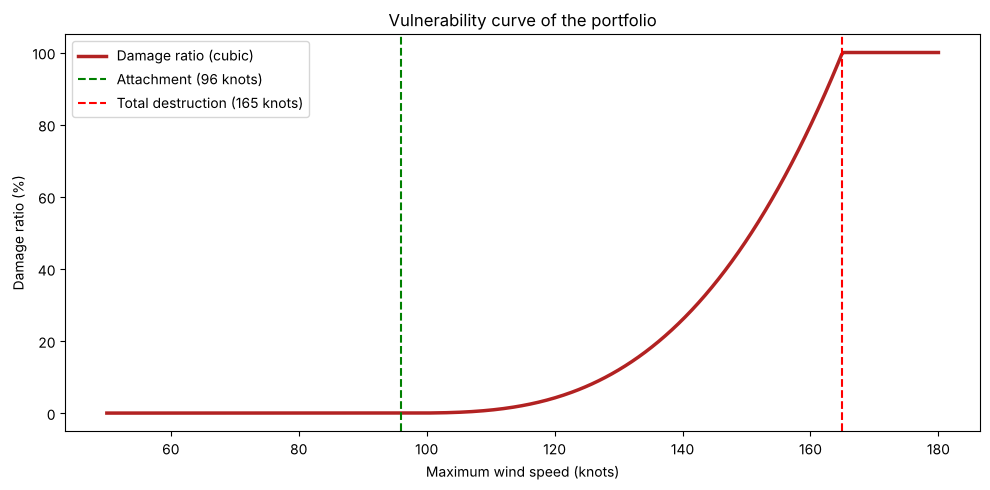

,Wind speed (knots),Severity,Damage ratio (%),Loss (M$)
0,85,Category 2 (no damage),0.00,0.0
1,96,Category 3 (attachment),0.00,0.0
2,110,Strong Category 3,0.84,41.8
3,130,Category 4 (major),11.96,598.2
4,145,Extreme Category 4,35.81,1790.7
5,160,Category 5,79.80,3989.9
6,165,Category 5+ (total destruction),100.00,5000.0
7,180,Above total destruction,100.00,5000.0


In [4]:
TIV = 5000       # Total Insured Value (M$)
V_MAX = 165      # wind speed of total destruction (knots)
POWER = 3.0

def damage_ratio(v, xm=XM, v_max=V_MAX, power=POWER):
    ratio = np.minimum(np.maximum(v - xm, 0) / (v_max - xm), 1.0)
    return ratio ** power

examples = pd.DataFrame({
    "Wind speed (knots)": [85, 96, 110, 130, 145, 160, 165, 180],
    "Severity": ["Category 2 (no damage)", "Category 3 (attachment)", "Strong Category 3",
                 "Category 4 (major)", "Extreme Category 4", "Category 5",
                 "Category 5+ (total destruction)", "Above total destruction"],
})
examples["Damage ratio (%)"] = (damage_ratio(examples["Wind speed (knots)"]) * 100).round(2)
examples["Loss (M$)"] = (damage_ratio(examples["Wind speed (knots)"]) * TIV).round(1)

v = np.linspace(50, 180, 500)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(v, damage_ratio(v) * 100, color="firebrick", lw=2.5, label="Damage ratio (cubic)")
ax.axvline(XM, color="green", ls="--", label=f"Attachment ({XM} knots)")
ax.axvline(V_MAX, color="red", ls="--", label=f"Total destruction ({V_MAX} knots)")
ax.set_xlabel("Maximum wind speed (knots)")
ax.set_ylabel("Damage ratio (%)")
ax.set_title("Vulnerability curve of the portfolio")
ax.legend()
plt.tight_layout()
plt.show()

examples

### 3. Monte Carlo simulation

To see how this model behaves, we simulate 10,000 years. To avoid slow Python loops, we vectorise everything with NumPy:

1. We draw the number of events of the 10,000 years at once (Poisson).
2. We draw one single Pareto vector for the wind speeds of all the events.
3. We apply the damage function to the whole vector.
4. We aggregate the losses by year with `np.bincount`.

A portfolio cannot lose more than its own value, so the annual loss is capped at the TIV.

In [5]:
class ALMEngine:
    def __init__(self, num_years=10_000, lambda_freq=lambda_hit, alpha=alpha, xm=XM,
                 v_max=V_MAX, power=POWER, tiv=TIV, seed=42):
        self.num_years = num_years
        self.lambda_freq = lambda_freq
        self.alpha = alpha
        self.xm = xm
        self.v_max = v_max
        self.power = power
        self.tiv = tiv
        self.rng = np.random.default_rng(seed)

    def generate_annual_losses(self):
        N = self.rng.poisson(self.lambda_freq, self.num_years)                  # events per year
        wind_speeds = self.xm * (self.rng.pareto(self.alpha, N.sum()) + 1)       # Pareto Type I
        losses = damage_ratio(wind_speeds, self.xm, self.v_max, self.power) * self.tiv

        year_index = np.repeat(np.arange(self.num_years), N)
        annual = np.bincount(year_index, weights=losses, minlength=self.num_years)
        annual = np.minimum(annual, self.tiv)                                     # cannot lose more than the TIV

        return pd.DataFrame({"Year": np.arange(1, self.num_years + 1),
                             "Num_Events": N,
                             "Aggregate_Loss_M": annual})

alm = ALMEngine()
sim = alm.generate_annual_losses()
annual_losses = sim["Aggregate_Loss_M"].values

print(f"Events simulated: {sim['Num_Events'].sum():,} over {alm.num_years:,} years")
print(f"Expected annual loss: {annual_losses.mean():,.1f} M$ ({annual_losses.mean() / TIV:.1%} of the TIV)")
print(f"Years with no loss: {(annual_losses == 0).mean():.1%}")
print(f"Years with a total loss of the portfolio: {(annual_losses >= TIV).mean():.1%}")

Events simulated: 3,205 over 10,000 years
Expected annual loss: 266.8 M$ (5.3% of the TIV)
Years with no loss: 72.4%
Years with a total loss of the portfolio: 3.1%


From this distribution, we can draw the AEP curve (Aggregate Exceedance Probability): for each return period, it gives the annual loss that is exceeded on average once every $T$ years. It also gives the Value at Risk (VaR) we will use to build the tranches.

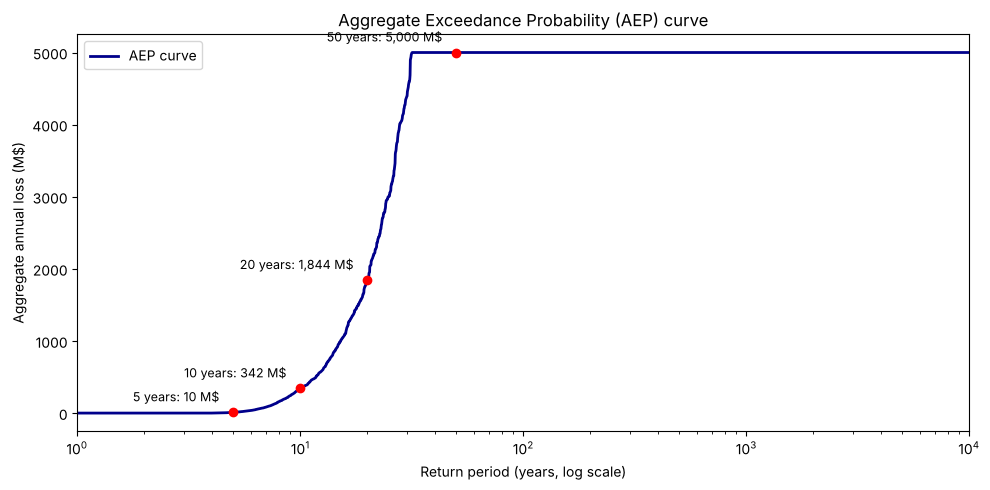

In [6]:
def plot_aep_curve(losses, return_periods=(5, 10, 20, 50)):
    sorted_losses = np.sort(losses)[::-1]
    exceedance_prob = np.arange(1, len(sorted_losses) + 1) / len(sorted_losses)
    return_period = 1 / exceedance_prob

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(return_period, sorted_losses, color="darkblue", lw=2, label="AEP curve")
    for rp in return_periods:
        loss_rp = sorted_losses[int(len(losses) / rp) - 1]
        ax.scatter(rp, loss_rp, color="red", zorder=3)
        ax.annotate(f"{rp} years: {loss_rp:,.0f} M$", (rp, loss_rp), textcoords="offset points",
                    xytext=(-10, 8), ha="right", fontsize=9)
    ax.set_xscale("log")
    ax.set_xlim(1, len(losses))
    ax.set_xlabel("Return period (years, log scale)")
    ax.set_ylabel("Aggregate annual loss (M$)")
    ax.set_title("Aggregate Exceedance Probability (AEP) curve")
    ax.legend()
    plt.tight_layout()
    plt.show()

plot_aep_curve(annual_losses)

The curve is flat at 5,000 M$ above a return period of about 30 years: in roughly 3% of the years, a Category 5 hurricane hits the portfolio and destroys it completely. This comes from our vulnerability curve, which reaches 100% of damage at 165 knots.

### 4. SPV engineering and tranching

The goal of this step is to cut the global risk $S$ into several layers inside the SPV. Each tranche $j$ is defined by:

- an attachment point $A_j$: the level of loss from which the tranche starts losing money,
- an exhaustion point $E_j$: the level of loss where the capital of the tranche is fully destroyed.

The principal of the tranche is $P_j = E_j - A_j$, and its loss is:

$$L_{tranche} = \min(\max(S - A_j, 0), P_j)$$

Rather than choosing arbitrary amounts, the tranches are anchored on the quantiles (the VaR) of our simulated loss distribution. As the losses are capped at the TIV, the Senior tranche goes up to the total destruction of the portfolio:

- **Junior**: between the VaR 80% and the VaR 90%. It absorbs the first losses.
- **Mezzanine**: between the VaR 90% and the VaR 95%.
- **Senior**: between the VaR 95% and the TIV (5,000 M$).

In [7]:
class Tranche:
    def __init__(self, name, attachment, exhaustion):
        self.name = name
        self.attachment = attachment
        self.exhaustion = exhaustion
        self.principal = exhaustion - attachment

    def calculate_losses(self, aggregate_losses):
        return np.minimum(np.maximum(aggregate_losses - self.attachment, 0), self.principal)


class SPV:
    def __init__(self, losses_distribution):
        self.losses_dist = np.asarray(losses_distribution)
        self.tranches = []

    def add_tranche(self, tranche):
        self.tranches.append(tranche)

    def analyze_structure(self):
        rows = []
        for t in self.tranches:
            tranche_losses = t.calculate_losses(self.losses_dist)
            rows.append({
                "Tranche": t.name,
                "Attachment (M$)": t.attachment,
                "Exhaustion (M$)": t.exhaustion,
                "Principal (M$)": t.principal,
                "Prob. attachment": np.mean(tranche_losses > 0),
                "Prob. exhaustion": np.mean(tranche_losses >= t.principal - 1e-5),
                "Expected loss (EL)": np.mean(tranche_losses) / t.principal,
            })
        return pd.DataFrame(rows)


var = {q: np.percentile(annual_losses, q) for q in (80, 90, 95)}

spv = SPV(annual_losses)
spv.add_tranche(Tranche("Junior", var[80], var[90]))
spv.add_tranche(Tranche("Mezzanine", var[90], var[95]))
spv.add_tranche(Tranche("Senior", var[95], TIV))

structure = spv.analyze_structure()
structure.style.format({
    "Attachment (M$)": "{:,.0f}", "Exhaustion (M$)": "{:,.0f}", "Principal (M$)": "{:,.0f}",
    "Prob. attachment": "{:.2%}", "Prob. exhaustion": "{:.2%}", "Expected loss (EL)": "{:.2%}",
}).hide(axis="index")

Tranche,Attachment (M$),Exhaustion (M$),Principal (M$),Prob. attachment,Prob. exhaustion,Expected loss (EL)
Junior,10,341,331,20.00%,10.00%,12.72%
Mezzanine,341,"1,839","1,499",10.00%,5.00%,6.65%
Senior,"1,839","5,000","3,161",5.00%,3.15%,3.89%


The key metric for investors is the Expected Loss (EL): the average annual loss of the tranche divided by its principal. Because of the 3% of years with a total loss, the exhaustion probability of the Mezzanine and the Senior tranches cannot go below 3%: in our model, the Senior tranche is far from risk-free.

### 5. Collateral and Total Return Swap (TRS)

The capital raised from investors is kept inside the SPV, so that the insurer is sure that the money will be available if a hurricane happens. This capital is invested in assets without credit risk: US Treasury bills.

But Treasury bills are exposed to interest rate risk: if rates go up, their price goes down, and the SPV could be unable to pay back the principal. To neutralise this risk, the arranger sets up a Total Return Swap with a bank:

1. SPV to the Bank: the SPV pays the whole performance of its Treasury bills portfolio.
2. Bank to the SPV: the bank pays a floating rate, the SOFR (3.64% in June 2026), minus its margin (15 basis points).

We simulate 12 months of a bond market crash on the capital of the Junior tranche, with and without the swap.

Without swap: 317.3 M$ (-13.5 M$)
With swap:    342.5 M$ (+11.7 M$, SOFR minus margin)
Total margin earned by the bank: 0.50 M$


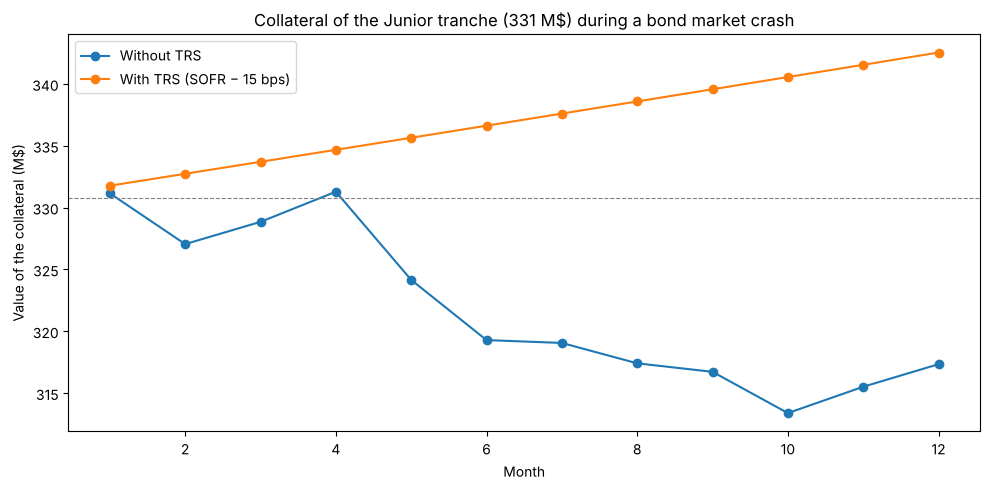

In [8]:
SOFR = 0.0364
TRS_MARGIN = 0.0015

class CollateralManager:
    """Capital management of the SPV, with and without a Total Return Swap."""
    def __init__(self, principal, months=12, sofr_annual=SOFR, trs_margin_annual=TRS_MARGIN, seed=42):
        self.principal = principal
        self.months = months
        self.sofr_monthly = sofr_annual / 12
        self.trs_margin_monthly = trs_margin_annual / 12
        self.rng = np.random.default_rng(seed)

    def run_trs_simulation(self):
        t_bill_returns = self.rng.normal(loc=-0.002, scale=0.01, size=self.months)  # bond market crash
        value_no_swap = value_with_swap = self.principal
        history = []
        for month, r in enumerate(t_bill_returns, start=1):
            value_no_swap += value_no_swap * r

            market_flow = value_with_swap * r                                        # T-bill performance
            paid_to_bank = market_flow                                               # given to the bank
            received_from_bank = value_with_swap * (self.sofr_monthly - self.trs_margin_monthly)
            bank_profit = value_with_swap * self.trs_margin_monthly
            value_with_swap += market_flow - paid_to_bank + received_from_bank

            history.append({"Month": month, "T-bill return": r,
                            "Net TRS flow (M$)": received_from_bank - paid_to_bank,
                            "Bank profit (M$)": bank_profit,
                            "SPV value without swap (M$)": value_no_swap,
                            "SPV value with swap (M$)": value_with_swap})
        return pd.DataFrame(history)


junior_principal = spv.tranches[0].principal
trs = CollateralManager(junior_principal).run_trs_simulation()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(trs["Month"], trs["SPV value without swap (M$)"], marker="o", label="Without TRS")
ax.plot(trs["Month"], trs["SPV value with swap (M$)"], marker="o", label="With TRS (SOFR − 15 bps)")
ax.axhline(junior_principal, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Month")
ax.set_ylabel("Value of the collateral (M$)")
ax.set_title(f"Collateral of the Junior tranche ({junior_principal:,.0f} M$) during a bond market crash")
ax.legend()
plt.tight_layout()
plt.show()

end_no, end_with = trs.iloc[-1][["SPV value without swap (M$)", "SPV value with swap (M$)"]]
print(f"Without swap: {end_no:,.1f} M$ ({end_no - junior_principal:+,.1f} M$)")
print(f"With swap:    {end_with:,.1f} M$ ({end_with - junior_principal:+,.1f} M$, SOFR minus margin)")
print(f"Total margin earned by the bank: {trs['Bank profit (M$)'].sum():,.2f} M$")

With the swap, the capital is protected whatever happens on the bond market, and the collateral earns a constant return:

$$R_{collateral} = SOFR - Margin_{TRS} = 3.64\% - 0.15\% = 3.49\%$$

### 6. Pricing at issuance

The investor requires two different remunerations:

- the return of the blocked capital: the risk-free return of the collateral (3.49%), thanks to the TRS,
- the remuneration of the climate risk: the premium paid directly by the insurer (the spread).

The spread is not simply equal to the Expected Loss, because investors always ask for an uncertainty premium. The price is set by applying a market multiple $M$ to the Expected Loss. After the heavy losses of the last years (hurricanes Ian and Idalia), the market is a hard market, and we take $M = 2.5$:

$$Spread = EL \times M \qquad \qquad Total\ Yield = R_{collateral} + Spread$$

In [9]:
class CatBondPricer:
    def __init__(self, sofr=SOFR, trs_margin=TRS_MARGIN, market_multiple=2.5):
        self.collateral_yield = sofr - trs_margin
        self.market_multiple = market_multiple

    def price_tranches(self, structure):
        out = structure[["Tranche", "Expected loss (EL)"]].copy()
        out["Spread (paid by the insurer)"] = out["Expected loss (EL)"] * self.market_multiple
        out["Collateral yield (TRS)"] = self.collateral_yield
        out["Total investor yield"] = out["Collateral yield (TRS)"] + out["Spread (paid by the insurer)"]
        return out


pricing = CatBondPricer().price_tranches(structure)
pricing.style.format({c: "{:.2%}" for c in pricing.columns if c != "Tranche"}).hide(axis="index")

Tranche,Expected loss (EL),Spread (paid by the insurer),Collateral yield (TRS),Total investor yield
Junior,12.72%,31.80%,3.49%,35.29%
Mezzanine,6.65%,16.61%,3.49%,20.10%
Senior,3.89%,9.73%,3.49%,13.22%


### 7. Limitations

- Hit probability: we assume that every major US landfall hits the whole portfolio. In reality, a portfolio is spread along the coast and a single landfall only hits part of it, so our losses are conservative.
- Wind speed: we use the maximum wind speed reached by each hurricane during its life, not its wind speed at landfall, which is often lower.
- Vulnerability curve: the total destruction at 165 knots creates a large probability (about 3% per year) of losing the whole portfolio, which makes the upper tranches riskier than real Senior cat bond tranches.
- Market multiple: we use a single multiple of 2.5x for all tranches, while in reality the multiple is usually higher for the safest tranches and lower for the riskiest ones.

### 8. Conclusion

This project goes through the whole life of a Cat Bond: from raw NOAA data to the yield paid to investors. The calibration on real data gives the frequency and the severity of major hurricanes, the vectorised Monte Carlo simulation gives the distribution of losses, and the SPV turns it into three tranches with very different risk profiles. Finally, the TRS protects the collateral against interest rate risk, and the market multiple turns the Expected Loss into a price.

I learnt that a model is only meaningful if its assumptions are consistent with each other: the frequency and the severity must describe the same events, and the portfolio cannot lose more than its own value. I also understood that a yield above 20% on a Junior tranche is not a mathematical anomaly, but the compensation for a risk of losing a large part of the capital in one year out of five.

**Sources:** NOAA National Hurricane Center (HURDAT2); NOAA NCEI (frequency of major US landfalls).